# Proyecto integrador IA · Segunda entrega · Equipo 3
**Sistema inteligente para monitoreo, clasificación y priorización del mantenimiento de infraestructura** (caso UNACH, referencia piloto ETDA).

> Todos los datos de este notebook son **simulados** (generados con `generador_datos.py`, semilla 2026) o **redactados a mano** por el equipo. No corresponden a reportes reales. Ninguna salida es un dictamen técnico: el prototipo propone una **prioridad preliminar** sujeta a revisión humana.

In [1]:
import json, warnings
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.max_colwidth', 90); pd.set_option('display.width', 200)
from evaluar import cargar, ejecutar_todo
from mantenimiento_ia import AgenteMantenimiento, crear_naive_bayes, detectar_senales

## 1. Datos simulados y casos externos

In [2]:
d, historial, ext = cargar()
print('Reportes simulados:', len(d), '| entrenamiento:', (d.grupo=='entrenamiento').sum(), '| prueba:', (d.grupo=='prueba').sum(), '| externos:', len(ext))
d[['id','fecha','zona','texto','foto_calidad','categoria_declarada','activo_id','plantilla','categoria_ref','prioridad_ref']].head(8)

Reportes simulados: 1400 | entrenamiento: 1052 | prueba: 348 | externos: 63


,id,fecha,zona,texto,foto_calidad,categoria_declarada,activo_id,plantilla,categoria_ref,prioridad_ref
0,S0001,2026-08-10,Aula 101,"oigan en aula 101 el soporte del proyector está colgando de un solo tornillo, lo vimos...",legible,MOBILIARIO,AUL73-MOB-09,T05,MOBILIARIO,Inmediata
1,S0002,2026-08-10,Aula 101,Reporte de incidencia: en Aula 101 el apagador tiene los cables expuestos. Favor de re...,legible,,AUL73-ELE-05,T03,ELECTRICO,Inmediata
2,S0003,2026-08-10,Auditorio,"un panel del plafon esta manchado y defromado, desde la semana pasada. aditorio.",legible,MUROS,AUD02-MUR-02,T10,MUROS,Media
3,S0004,2026-08-10,Biblioteca,"Por medio de la presente informo que el techo tiene goteras en Biblioteca, lo vimos va...",legible,,BIB95-HUM-11,T02,HUMEDAD,Media
4,S0005,2026-08-10,Aula 203,"reisar aula 203 - un escalon tiene la nariz rota, desde la semana pasada",legible,,AUL65-PIS-09,T11,PISOS,Alta
5,S0006,2026-08-10,Pasillo planta baja,"Al salir de Pasllo planta baja vi que el muro del pasillo esta rayada con grafiti, por...",legible,,,T16,MUROS,Baja
6,S0007,2026-08-10,Laboratorio de redes,"revisar Laboratorio de redes - el piso de la escalera esta muy resbaloso, lo vimos var...",legible,,,T11,PISOS,Alta
7,S0008,2026-08-10,Aula 305,"revisar aula 305 - los contactos de la pared esta flojo y se salen las clavijas, desde...",legible,ELECTRICO,AUL15-ELE-12,T11,ELECTRICO,Alta


In [3]:
pd.crosstab(d.plantilla, d.grupo)

grupo,entrenamiento,prueba
plantilla,,
T01,81,0
T02,94,0
T03,0,96
T04,88,0
T05,0,80
T06,94,0
T07,95,0
T08,86,0
T09,108,0


In [4]:
ext[['id','texto','categoria_ref','senales_ref','prioridad_ref']].head(8)

,id,texto,categoria_ref,senales_ref,prioridad_ref
0,X01,Cada que llueve se mete el agua por el marco de la ventana y baja por la pared,HUMEDAD,agua,Media
1,X02,"El techo del aula está todo chorreado y huele a encerrado, como a moho",HUMEDAD,agua,Media
2,X03,"Hay salitre en la parte de abajo de la pared, se está haciendo polvo el aplanado",HUMEDAD,agua,Media
3,X04,Se está trasminando la humedad del jardín hacia la pared de la biblioteca,HUMEDAD,agua,Media
4,X05,En la sala de maestros cae agüita del plafón justo encima del multicontacto donde carg...,HUMEDAD,agua|electrico,Inmediata
5,X06,"Quedó una aureola café en el techo de cuando hubo goteras el año pasado, ya no cae nada",HUMEDAD,estetico,Baja
6,X07,Después del aguacero se hizo un lago en la entrada del edificio B y la gente se está p...,HUMEDAD,agua|circulacion,Alta
7,X08,La pared del auditorio tiene manchas verdes de hongo y se siente mojada,HUMEDAD,agua,Media


## 2. Entrenamiento y evaluación completa
`ejecutar_todo()` repite exactamente el protocolo de `evaluar.py`. Se comprueba que las cifras coincidan con `resultados/metricas.json`.

In [5]:
m, pruebas, res_te, res_ex, nb = ejecutar_todo(guardar=False)
guardado = json.load(open('resultados/metricas.json', encoding='utf-8'))
print('¿Cifras idénticas a resultados/metricas.json?', json.dumps(m, sort_keys=True, default=str) == json.dumps(guardado, sort_keys=True, default=str))
print('alpha NB:', m['seleccion']['alpha_nb'], '| C LR:', m['seleccion']['C_lr'], '| umbral:', m['umbral']['valor'])

¿Cifras idénticas a resultados/metricas.json? True
alpha NB: 0.05 | C LR: 10.0 | umbral: 0.2


## 3. Clasificador de categoría

In [6]:
filas = []
for conj in ('prueba', 'externos', 'aleatoria'):
    for mod in ('palabras_clave', 'naive_bayes', 'regresion_logistica'):
        x = m['clasificador'][conj][mod]; filas.append({'conjunto': conj, 'modelo': mod, **{k: round(v, 3) for k, v in x.items() if k != 'n'}, 'n': x['n']})
pd.DataFrame(filas)

,conjunto,modelo,exactitud,precision_macro,recall_macro,f1_macro,n
0,prueba,palabras_clave,0.819,0.907,0.815,0.847,348
1,prueba,naive_bayes,0.966,0.966,0.965,0.965,348
2,prueba,regresion_logistica,0.963,0.963,0.962,0.962,348
3,externos,palabras_clave,0.825,0.894,0.825,0.830,63
4,externos,naive_bayes,0.714,0.721,0.714,0.714,63
5,externos,regresion_logistica,0.794,0.802,0.794,0.793,63
6,aleatoria,palabras_clave,0.819,0.885,0.819,0.840,348
7,aleatoria,naive_bayes,0.977,0.978,0.977,0.977,348
8,aleatoria,regresion_logistica,0.980,0.981,0.980,0.980,348


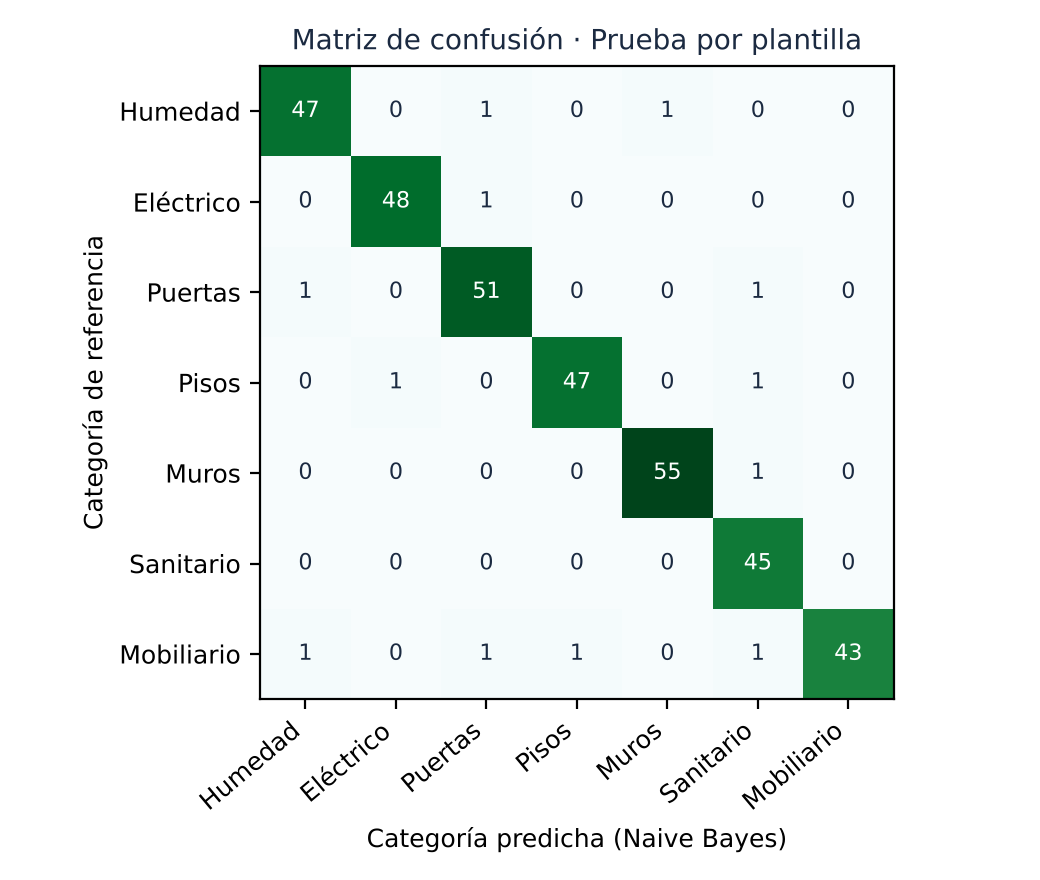

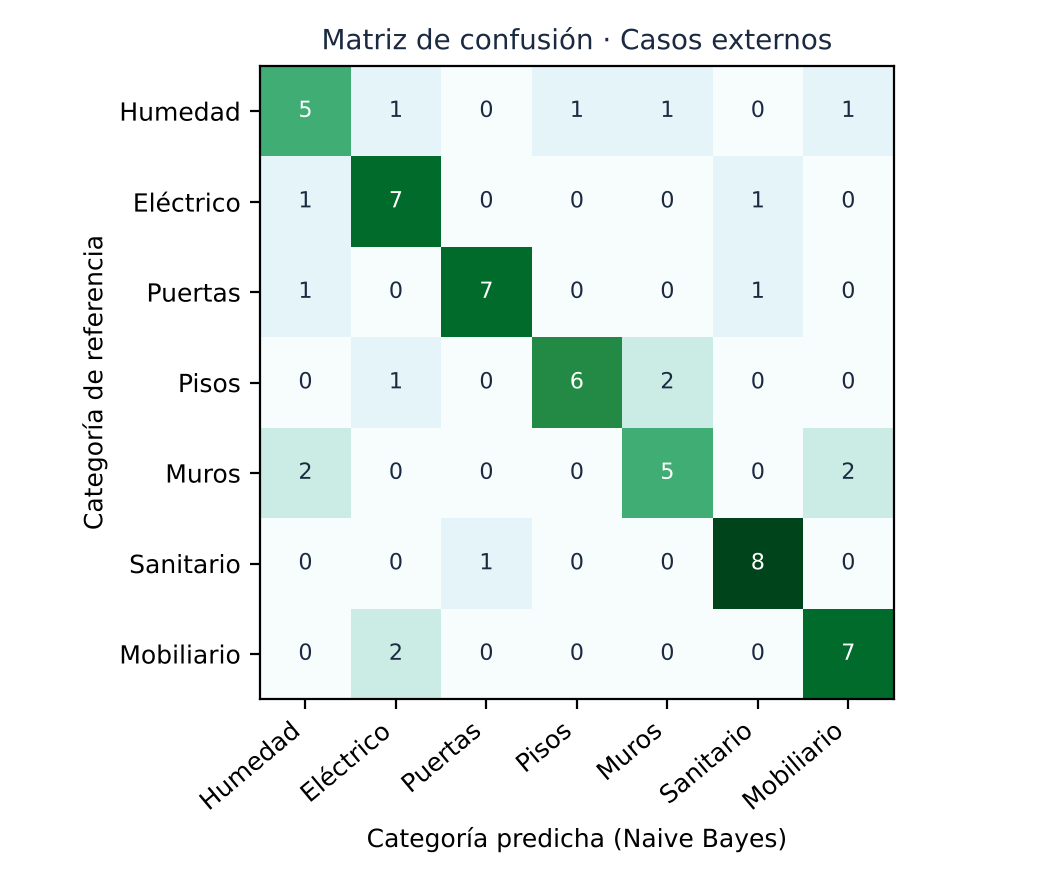

In [7]:
display(Image('resultados/figuras/matriz_nb_prueba.png', width=430)); display(Image('resultados/figuras/matriz_nb_externos.png', width=430))

{'criterio': 'menor umbral con error <= 0.10 entre los casos aceptados (validación agrupada en entrenamiento)', 'valor': np.float64(0.2), 'cobertura_validacion': 1.0, 'error_aceptados_validacion': 0.02376425855513308, 'exactitud_oof': 0.9762357414448669}


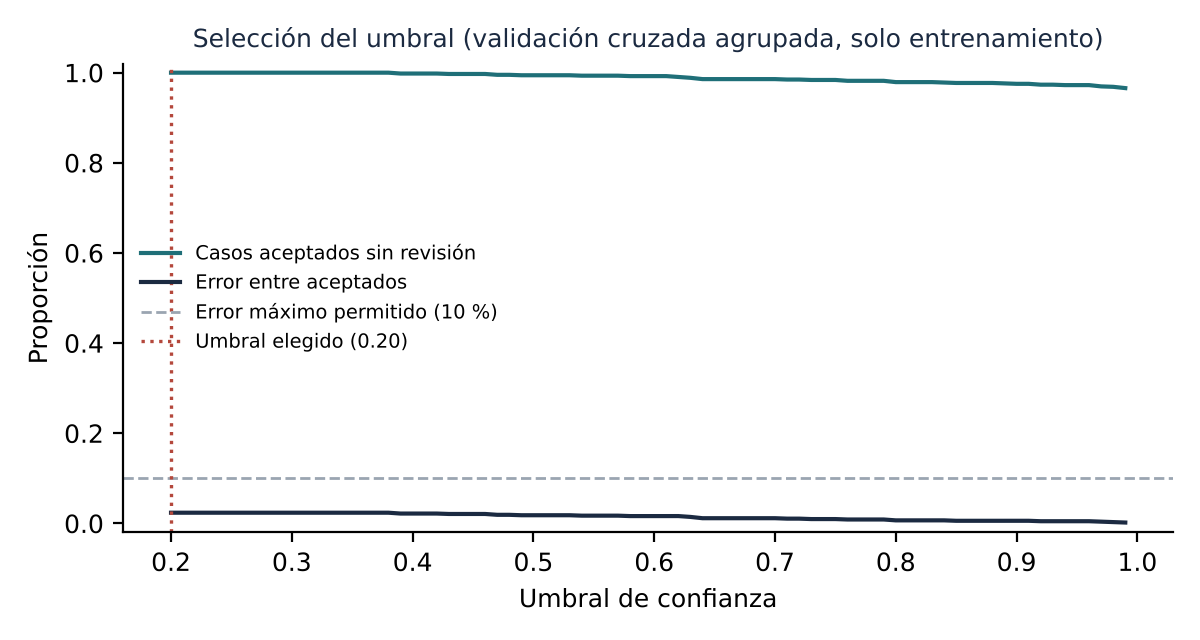

In [8]:
print(m['umbral']); display(Image('resultados/figuras/umbral_validacion.png', width=560))

## 4. Señales de riesgo detectadas en el texto (lexicón)

In [9]:
pd.DataFrame({c: {s: (round(v['recall'], 3) if v['recall'] is not None else None) for s, v in m['senales'][c].items()} for c in ('prueba', 'externos')}).rename(columns=lambda c: 'recall_' + c)

,recall_prueba,recall_externos
agua,0.937,0.769
electrico,0.685,0.833
riesgo_electrico,1.000,0.500
desprendimiento,1.000,0.000
estructural,1.000,0.500
circulacion,0.800,0.286
sin_servicio,1.000,0.000
estetico,0.644,0.857


## 5. Prioridad preliminar: prototipo frente a líneas base

In [10]:
cols = ['exactitud_prioridad','recall_criticos','falsos_negativos_criticos','fn_criticos_sin_revision','falsas_alarmas','proporcion_revision_humana','subestimacion']
for conj in ('prueba', 'externos'):
    print('==', conj)
    display(pd.DataFrame(m['prioridad'][conj]).T[cols])

== prueba


,exactitud_prioridad,recall_criticos,falsos_negativos_criticos,fn_criticos_sin_revision,falsas_alarmas,proporcion_revision_humana,subestimacion
B0_todo_media_orden_llegada,0.425287,0.0,53,53,0,0.0,0.465517
B1_palabras_clave_tabla_fija,0.41954,0.226415,41,41,26,0.0,0.454023
A1_reglas_con_palabras_clave,0.804598,1.0,0,0,2,0.344828,0.066092
A2_reglas_con_categoria_real,0.807471,1.0,0,0,1,0.252874,0.066092
PROTOTIPO_NB_mas_reglas,0.807471,1.0,0,0,1,0.270115,0.066092
PROTOTIPO_tras_confirmacion_R5,0.876437,1.0,0,0,1,0.270115,0.068966


== externos


,exactitud_prioridad,recall_criticos,falsos_negativos_criticos,fn_criticos_sin_revision,falsas_alarmas,proporcion_revision_humana,subestimacion
B0_todo_media_orden_llegada,0.52381,0.0,15,15,0,0.0,0.365079
B1_palabras_clave_tabla_fija,0.428571,0.2,12,12,5,0.0,0.412698
A1_reglas_con_palabras_clave,0.603175,0.333333,10,10,3,0.142857,0.222222
A2_reglas_con_categoria_real,0.619048,0.4,9,9,3,0.142857,0.206349
PROTOTIPO_NB_mas_reglas,0.587302,0.333333,10,10,4,0.142857,0.222222
PROTOTIPO_tras_confirmacion_R5,0.68254,0.333333,10,10,4,0.142857,0.222222


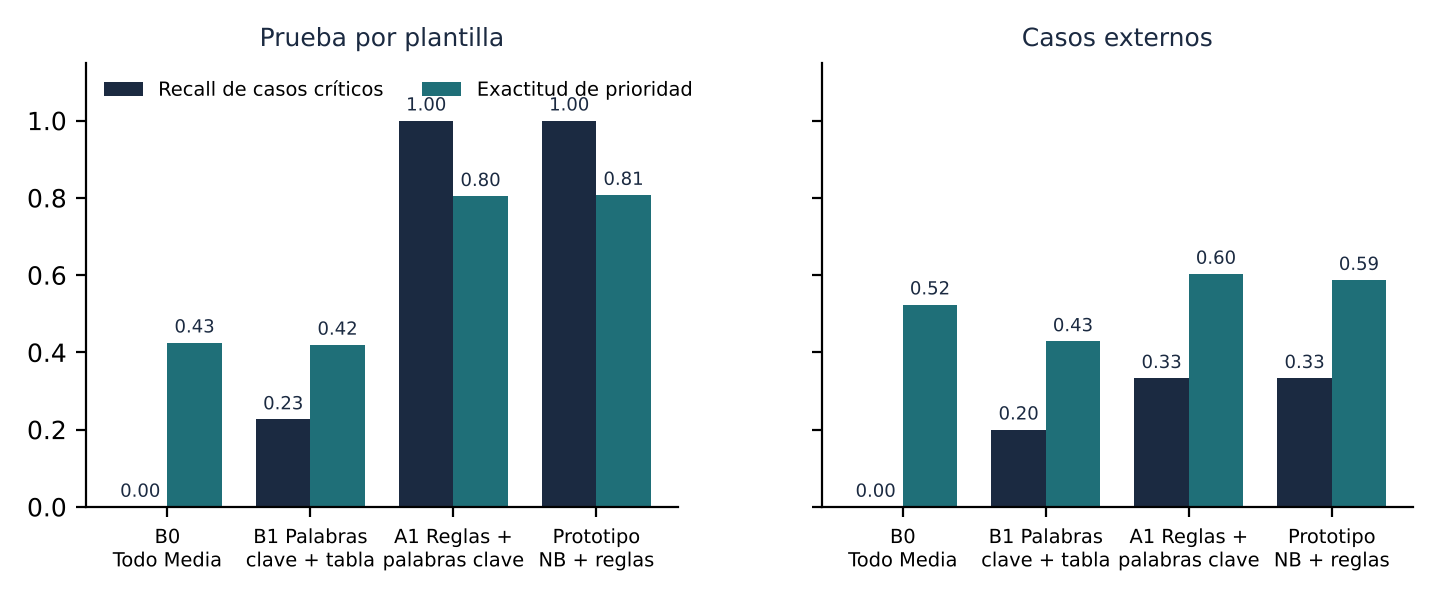

R4 duplicados (prueba): {'duplicados_reales': 25, 'vinculados_correctamente': 20, 'recall_duplicados': 0.8, 'vinculaciones_totales': 38, 'vinculaciones_incorrectas': 17, 'precision_vinculacion': 0.5263157894736842}


In [11]:
display(Image('resultados/figuras/comparacion_sistemas.png', width=640))
print('R4 duplicados (prueba):', m['duplicados_R4_prueba'])

## 6. Pruebas con resultado esperado definido antes de ejecutar

In [12]:
pd.DataFrame([{'id': p['id'], 'regla': p['regla'], 'correcto': p['correcto'], 'fallas': p['fallas'], 'prioridad': p['obtenido']['prioridad'], 'reglas': p['obtenido']['reglas']} for p in pruebas['pruebas']])

,id,regla,correcto,fallas,prioridad,reglas
0,P01,R1,True,[],Inmediata,[R1]
1,P02,R2,True,[],Inmediata,[R2]
2,P03,R3,False,[revision_humana],Media,[R3]
3,P04,R4,True,[],Media,[]
4,P05,R5,True,[],Media,[]
5,P06,R6,True,[],Media,[]
6,P07,R7,True,[],Media,[R7]
7,P08,R1 (negación),True,[],Media,[]
8,P09,R9,True,[],Alta,[R9]
9,P10,R8,True,[],Media,[R8]


## 7. El agente en acción: percibir → interpretar → decidir → actuar → retroalimentar

In [13]:
tr = d[d.grupo=='entrenamiento']
agente = AgenteMantenimiento(nb, m['umbral']['valor'], historial, tr.texto.values)
salida = agente.procesar({'id': 'NB1', 'fecha': '2026-10-25', 'zona': 'Biblioteca', 'foto_calidad': 'legible',
                          'texto': 'Se está filtrando agua por el plafón justo arriba del tablero eléctrico'})
for etapa in ('interpretacion', 'decision', 'accion'):
    print(etapa.upper(), {k: v for k, v in salida[etapa].items() if k != 'senales_efectivas'})

INTERPRETACION {'categoria': 'HUMEDAD', 'confianza': 0.9971376856018616, 'alternativas': [('HUMEDAD', 0.997), ('SANITARIO', 0.003), ('ELECTRICO', 0.0)], 'palabras_clave': [('agua', 4.63), ('plafon', 3.76), ('arriba', 2.93)], 'senales_texto': {'agua': True, 'electrico': True, 'riesgo_electrico': False, 'desprendimiento': False, 'estructural': False, 'circulacion': False, 'sin_servicio': False, 'estetico': False}, 'evidencia': {'agua': ['filtr', 'agua'], 'electrico': ['tablero', 'electric']}}
DECISION {'categoria': 'HUMEDAD', 'area': 'Mantenimiento general / impermeabilización', 'prioridad': 'Inmediata', 'escalamiento': True, 'revision_humana': True, 'motivos_revision': ['señal de riesgo que exige valoración competente'], 'reglas': ['R1'], 'motivos_prioridad': ['agua o humedad cerca de un elemento eléctrico'], 'acciones': ['crear_caso', 'alertar_area_competente'], 'candidato_estetico': False, 'reincidencia': False, 'incidencias_previas': 0}
ACCION {'caso_id': 'C0001', 'vinculado': False,

In [14]:
salida2 = agente.procesar({'id': 'NB2', 'fecha': '2026-10-25', 'zona': 'Aula 203', 'foto_calidad': 'legible', 'texto': 'La pintura de la pared está descarapelada'})
caso = agente.retroalimentar(salida2['accion']['caso_id'], 'Responsable (simulado)', '2026-10-26', solo_estetico=True)
print('Prioridad tras confirmación R5:', caso.prioridad)
print(agente.correcciones[-1])
pd.DataFrame(agente.panel('2026-10-26'))

Prioridad tras confirmación R5: Baja
{'caso_id': 'C0002', 'autor': 'Responsable (simulado)', 'fecha': '2026-10-26', 'antes': {'categoria': 'MUROS', 'prioridad': 'Media', 'estado': 'pendiente_revision'}, 'despues': {'categoria': 'MUROS', 'prioridad': 'Baja', 'estado': 'validado'}, 'nota': ''}


,caso,zona,categoria,prioridad,estado,dias_abierto,aviso_antiguedad,reportes_vinculados
0,C0001,Biblioteca,HUMEDAD,Inmediata,pendiente_revision,1,False,1
1,C0002,Aula 203,MUROS,Baja,validado,1,False,1


## 8. Ejemplos de error (casos externos)

In [15]:
e = res_ex[res_ex.categoria_ref != res_ex.categoria_pred][['id','texto','categoria_ref','categoria_pred','confianza','palabras_clave']]
e.head(10)

,id,texto,categoria_ref,categoria_pred,confianza,palabras_clave
1,X02,"El techo del aula está todo chorreado y huele a encerrado, como a moho",HUMEDAD,ELECTRICO,0.979884,todo (5.58); huele (4.48); aula todo (3.58)
4,X05,En la sala de maestros cae agüita del plafón justo encima del multicontacto donde carg...,HUMEDAD,MUROS,0.635533,plafon (6.13); sala (0.58); sala maestros (0.58)
6,X07,Después del aguacero se hizo un lago en la entrada del edificio B y la gente se está p...,HUMEDAD,PISOS,0.910694,gente (4.78); entrada (2.67); edificio (1.77)
7,X08,La pared del auditorio tiene manchas verdes de hongo y se siente mojada,HUMEDAD,MOBILIARIO,0.832287,pared auditorio (3.83); pared (3.71); auditorio (2.31)
9,X10,"Se botó el foco del baño de hombres, está oscuro",ELECTRICO,SANITARIO,0.960250,bano (5.67); hombres (4.01)
13,X14,"Hay un cable colgando del techo pelado, sin cinta, a la altura de la cabeza",ELECTRICO,HUMEDAD,0.497617,techo (5.41); sin (1.98)
24,X25,"El cerrojo del baño de mujeres no sirve, no se puede cerrar",PUERTAS,SANITARIO,1.000000,bano (5.67); mujeres no (4.29); no puede (3.61)
26,X27,Le falta el tope a la puerta y golpea la pared cada que la abren,PUERTAS,HUMEDAD,0.455322,puerta (2.95); pared (2.89)
28,X29,En la rampa de acceso falta un pedazo de concreto y se atoran las sillas de ruedas,PISOS,MUROS,0.969113,pedazo (5.28)
32,X33,"Los escalones de la entrada están muy lisos, ya se cayó una maestra",PISOS,MUROS,0.947447,cayo (5.16); entrada (0.89)


In [16]:
res_ex[(res_ex.critico_ref) & ~((res_ex.prioridad_pred=='Inmediata') | res_ex.escalamiento_pred)][['id','texto','senales_ref','senales_detectadas','prioridad_ref','prioridad_pred']]

,id,texto,senales_ref,senales_detectadas,prioridad_ref,prioridad_pred
4,X05,En la sala de maestros cae agüita del plafón justo encima del multicontacto donde carg...,agua|electrico,electrico,Inmediata,Media
8,X09,Por la junta del techo se cuela el agua y cae directo sobre el proyector,agua|electrico,agua,Inmediata,Media
11,X12,El apagador del aula 204 está achicharrado y cuando lo prendes saca chispitas,electrico|riesgo_electrico,electrico,Inmediata,Media
17,X18,El tablero de la planta baja está abierto y se le ven los fusibles,electrico|riesgo_electrico,electrico,Inmediata,Media
35,X36,Se hundió un poco el piso junto a la jardinera y se hace un escalón,circulacion|estructural,circulacion,Alta,Alta
38,X39,Se ve una cuarteadura que atraviesa la pared del aula 203 de esquina a esquina,estructural,,Alta,Media
39,X40,Se está botando el aplanado del muro y caen pedacitos,desprendimiento,,Inmediata,Media
40,X41,"Una placa del plafón está chueca, como que se va a zafar",desprendimiento,,Inmediata,Media
55,X56,El pintarrón se está despegando de la pared y se ladea,desprendimiento,,Inmediata,Media
62,X63,El anaquel de la biblioteca está ladeado y los libros se le pueden venir encima a alguien,desprendimiento,,Inmediata,Media
